In [3]:
import pandas as pd

In [4]:
x_train = pd.read_csv('data/x_train_final.csv', index_col=0)
x_train.drop(columns=["Unnamed: 0"], inplace=True)

y_train = pd.read_csv('data/y_train_final.csv', index_col=0)

In [5]:
x_train

,train,gare,date,arret,p2q0,p3q0,p4q0,p0q2,p0q3,p0q4
0,VBXNMF,KYF,2023-04-03,8,0.0,0.0,1.0,-3.0,-1.0,-2.0
1,VBXNMF,JLR,2023-04-03,9,0.0,0.0,0.0,1.0,0.0,1.0
2,VBXNMF,EOH,2023-04-03,10,-1.0,0.0,0.0,-1.0,0.0,0.0
3,VBXNMF,VXY,2023-04-03,11,-1.0,-1.0,0.0,2.0,-2.0,0.0
4,VBXNMF,OCB,2023-04-03,12,-1.0,-1.0,-1.0,-1.0,3.0,2.0
...,...,...,...,...,...,...,...,...,...,...
667259,BFNJJK,DGG,2023-11-10,22,0.0,-1.0,-6.0,-1.0,0.0,-2.0
667260,BFNJJK,KDN,2023-11-10,23,0.0,0.0,-1.0,1.0,0.0,0.0
667261,BFNJJK,TVD,2023-11-10,24,1.0,0.0,0.0,-1.0,-3.0,-1.0
667262,BFNJJK,TXP,2023-11-10,26,2.0,2.0,1.0,0.0,0.0,1.0


In [6]:
y_train

,p0q0
0,-1.0
1,-1.0
2,-1.0
3,1.0
4,3.0
...,...
667259,1.0
667260,2.0
667261,2.0
667262,1.0


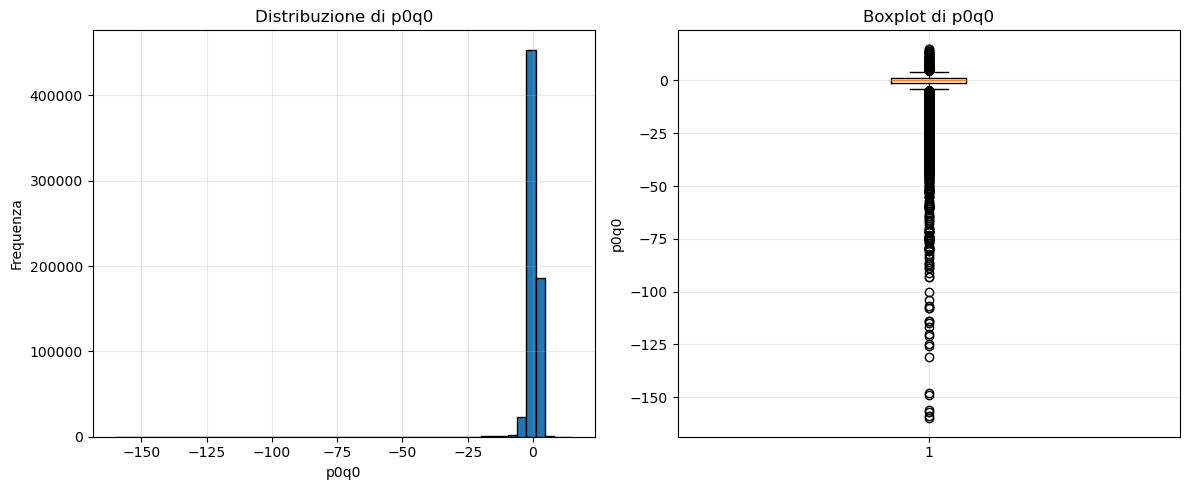

count    667264.000000
mean         -0.159950
std           1.987872
min        -160.000000
25%          -1.000000
50%           0.000000
75%           1.000000
max          15.000000
Name: p0q0, dtype: float64


In [5]:
import matplotlib.pyplot as plt

y = y_train.iloc[:, 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Istogramma
axes[0].hist(y, bins=50, edgecolor="black")
axes[0].set_xlabel("p0q0")
axes[0].set_ylabel("Frequenza")
axes[0].set_title("Distribuzione di p0q0")
axes[0].grid(alpha=0.3)

# Boxplot per vedere outlier
axes[1].boxplot(y, vert=True)
axes[1].set_ylabel("p0q0")
axes[1].set_title("Boxplot di p0q0")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(y.describe())

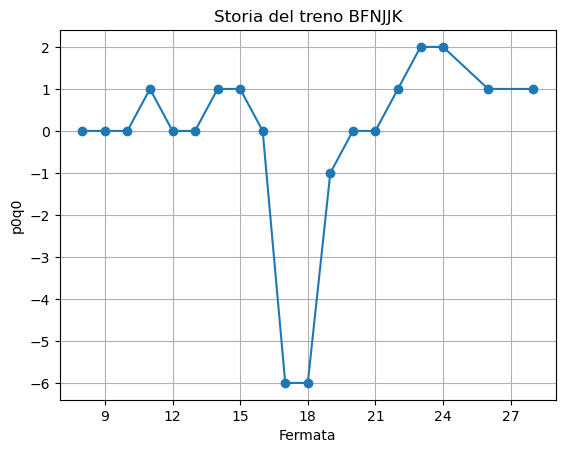

In [14]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

treno = "BFNJJK"
storia = x_train[x_train["train"] == treno].copy()
storia["p0q0"] = y_train.loc[storia.index].iloc[:, 0]
storia = storia.sort_values("arret")

# Plot
fig, ax = plt.subplots()
ax.plot(storia["arret"].astype(int), storia["p0q0"], marker="o")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Fermata")
ax.set_ylabel("p0q0")
ax.set_title(f"Storia del treno {treno}")
ax.grid()
plt.show()

In [19]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# --- Caricamento dati ---
x_train = pd.read_csv('data/x_train_final.csv', index_col=0)
x_train.drop(columns=["Unnamed: 0"], inplace=True, errors="ignore")
y_train = pd.read_csv('data/y_train_final.csv', index_col=0)

df = x_train.copy()
df["date"] = pd.to_datetime(df["date"])
df["target"] = y_train.iloc[:, 0].values

# --- Feature engineering minimo ---
df["dow"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month
df["is_weekend"] = df["dow"].isin([5, 6]).astype(int)

# encoding stazione: frequency encoding (semplice, no leakage)
freq_gare = df["gare"].value_counts(normalize=True)
df["gare_freq"] = df["gare"].map(freq_gare)

# --- Split temporale (NON random) ---
date_split = df["date"].quantile(0.8)
train_mask = df["date"] <= date_split

feature_cols = [
    "arret", "p2q0", "p3q0", "p4q0", "p0q2", "p0q3", "p0q4",
    "dow", "month", "is_weekend", "gare_freq"
]

X_tr, X_val = df.loc[train_mask, feature_cols], df.loc[~train_mask, feature_cols]
y_tr, y_val = df.loc[train_mask, "target"], df.loc[~train_mask, "target"]

# --- Gestione NaN (RF di sklearn NON accetta NaN nativamente) ---
X_tr = X_tr.fillna(-999)
X_val = X_val.fillna(-999)

# --- Modello ---
rf = RandomForestRegressor(
    n_estimators=50,
    max_depth=None,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42,
    verbose=2,  # stampa aggiornamenti durante il fit
)
rf.fit(X_tr, y_tr)

# --- Valutazione ---
pred_val = rf.predict(X_val)
mae = mean_absolute_error(y_val, pred_val)
print(f"MAE validation: {mae:.4f}")

# --- Feature importance ---
importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importances)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.


building tree 1 of 50building tree 2 of 50
building tree 3 of 50

building tree 4 of 50
building tree 5 of 50
building tree 6 of 50
building tree 7 of 50
building tree 8 of 50
building tree 9 of 50
building tree 10 of 50
building tree 11 of 50
building tree 12 of 50
building tree 13 of 50
building tree 14 of 50
building tree 15 of 50
building tree 16 of 50
building tree 17 of 50
building tree 18 of 50
building tree 19 of 50
building tree 20 of 50
building tree 21 of 50
building tree 22 of 50
building tree 23 of 50
building tree 24 of 50
building tree 25 of 50
building tree 26 of 50
building tree 27 of 50
building tree 28 of 50
building tree 29 of 50
building tree 30 of 50
building tree 31 of 50
building tree 32 of 50
building tree 33 of 50
building tree 34 of 50
building tree 35 of 50
building tree 36 of 50


[Parallel(n_jobs=-1)]: Done  25 tasks      | elapsed:  1.1min


building tree 37 of 50
building tree 38 of 50
building tree 39 of 50
building tree 40 of 50
building tree 41 of 50
building tree 42 of 50
building tree 43 of 50
building tree 44 of 50
building tree 45 of 50
building tree 46 of 50
building tree 47 of 50
building tree 48 of 50
building tree 49 of 50
building tree 50 of 50


[Parallel(n_jobs=-1)]: Done  50 out of  50 | elapsed:  1.6min finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  25 tasks      | elapsed:    1.0s


MAE validation: 0.7758
p0q2          0.181076
gare_freq     0.176513
arret         0.145046
p0q4          0.091159
p0q3          0.088012
p2q0          0.079858
dow           0.065313
month         0.063159
p4q0          0.055452
p3q0          0.054410
is_weekend    0.000000
dtype: float64


[Parallel(n_jobs=8)]: Done  50 out of  50 | elapsed:    2.1s finished
